In [1]:
# ============================================================================
# BiLSTM Multi-Task Complaint Classification - COMPLETE NOTEBOOK
# Replaces MURIL/BERT with BiLSTM architecture
# ============================================================================

# ----------------------------------------------------------------------------
# CELL 1: IMPORTS AND SYSTEM SETUP
# ----------------------------------------------------------------------------

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
import re
from collections import Counter
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.cuda.amp import GradScaler, autocast

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    precision_recall_fscore_support
)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# Set random seeds
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

set_seed(42)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [2]:
# ----------------------------------------------------------------------------
# CELL 2: CONFIGURATION
# ----------------------------------------------------------------------------

class Config:
    """Configuration settings for BiLSTM"""
    
    BASE_MODEL = 'bilstm'
    
    # Directories
    PROJECT_DIR = os.getcwd()
    DATA_DIR = os.path.join(PROJECT_DIR, "Common_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")
    
    # Output - Separate directory for BiLSTM results
    BASE_DIR = os.path.join(PROJECT_DIR, "bilstm_results_CD")
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    
    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, RESULTS_DIR]:
        os.makedirs(dir_path, exist_ok=True)
    
    # Tokenizer / Vocabulary
    MAX_LENGTH = 256          # starting value; CELL 6 re-sets it from the data
    MAX_LENGTH_CAP = 400      # upper bound for the data-driven MAX_LENGTH
    # Language name -> column in the PREPROCESSED dataframes (after the rename in CELL 5)
    LANGUAGE_COLUMNS = {'English': 'text_en', 'Hindi': 'Hindi', 'Hinglish': 'Hinglish'}
    MAX_VOCAB_SIZE = 50000
    MIN_FREQ = 2
    EMBEDDING_DIM = 300
    HIDDEN_DIM = 256
    NUM_LAYERS = 2
    BIDIRECTIONAL = True
    
    # Training
    BATCH_SIZE = 64
    EPOCHS = 20
    LEARNING_RATE = 1e-3
    DROPOUT = 0.3
    WEIGHT_DECAY = 1e-4
    WARMUP_RATIO = 0.1
    NUM_WORKERS = 0  # Windows compatibility
    GRAD_CLIP = 1.0
    
    # Device
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42


print("=" * 80)
print("BILSTM CONFIGURATION")
print("=" * 80)
print(f"\n[BATCH SIZE] {Config.BATCH_SIZE}")
print(f"[EPOCHS] {Config.EPOCHS}")
print(f"[LEARNING RATE] {Config.LEARNING_RATE}")
print(f"[DEVICE] {Config.DEVICE}")
print(f"[EMBEDDING DIM] {Config.EMBEDDING_DIM}")
print(f"[HIDDEN DIM] {Config.HIDDEN_DIM}")
print(f"[NUM LAYERS] {Config.NUM_LAYERS}")
print("=" * 80)

BILSTM CONFIGURATION

[BATCH SIZE] 64
[EPOCHS] 20
[LEARNING RATE] 0.001
[DEVICE] cuda
[EMBEDDING DIM] 300
[HIDDEN DIM] 256
[NUM LAYERS] 2


In [3]:
# ----------------------------------------------------------------------------
# CELL 3: LOAD DATA
# ----------------------------------------------------------------------------

print("Loading datasets...")
train_df = pd.read_csv(Config.TRAIN_PATH)
dev_df = pd.read_csv(Config.DEV_PATH)
test_df = pd.read_csv(Config.TEST_PATH)
print(f"Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")

print("\nPrimary Category Distribution (Train):")
print(train_df['primary_category'].value_counts())

print("\nSeverity Distribution (Train):")
print(train_df['Severity'].value_counts())

Loading datasets...
Train: 14165, Dev: 3035, Test: 3036

Primary Category Distribution (Train):
primary_category
Road & Transportation                  2710
Waste Management                       2075
Electricity                            1908
Others                                 1616
Water Leakage                          1573
Health & Sanitation                    1470
Public Safety                          1408
Encroachment & Illegal Construction    1405
Name: count, dtype: int64

Severity Distribution (Train):
Severity
Low       5898
Medium    4290
High      3977
Name: count, dtype: int64


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14165 entries, 0 to 14164
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Sy_No               14165 non-null  int64 
 1   Complaint_Title     14165 non-null  object
 2   Text_en             14165 non-null  object
 3   Text_hi             14165 non-null  object
 4   Text_hinglish       14165 non-null  object
 5   primary_category    14165 non-null  object
 6   secondary_category  14165 non-null  object
 7   Severity            14165 non-null  object
 8   Model_Name          10528 non-null  object
dtypes: int64(1), object(8)
memory usage: 996.1+ KB


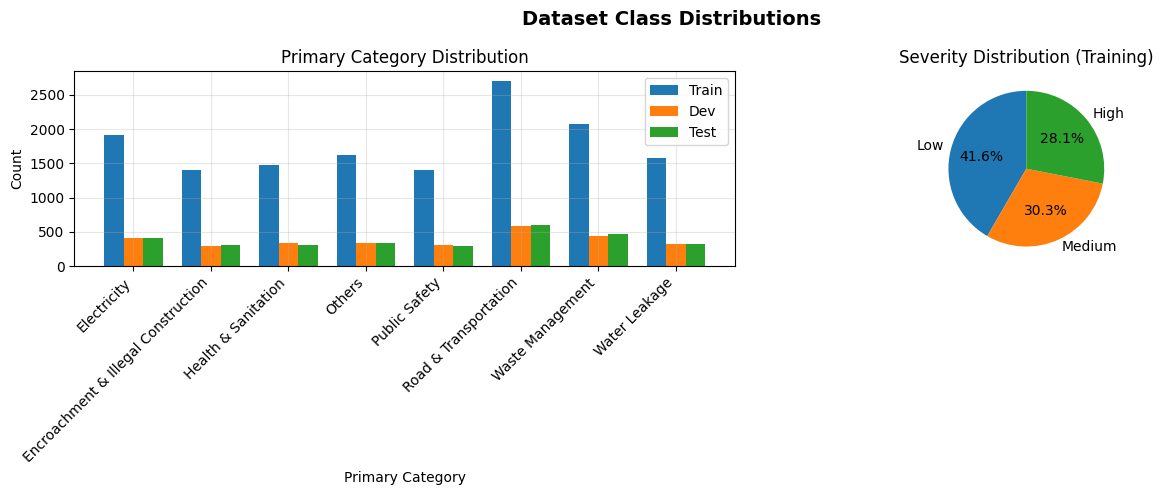

In [5]:
# ----------------------------------------------------------------------------
# CELL 4: VISUALIZE CLASS DISTRIBUTIONS
# ----------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_counts = train_df['primary_category'].value_counts()
dev_counts = dev_df['primary_category'].value_counts()
test_counts = test_df['primary_category'].value_counts()

categories = sorted(train_counts.index.tolist())
x = np.arange(len(categories))
width = 0.25

axes[0].bar(x - width, [train_counts.get(c, 0) for c in categories], width, label='Train')
axes[0].bar(x, [dev_counts.get(c, 0) for c in categories], width, label='Dev')
axes[0].bar(x + width, [test_counts.get(c, 0) for c in categories], width, label='Test')
axes[0].set_xlabel('Primary Category')
axes[0].set_ylabel('Count')
axes[0].set_title('Primary Category Distribution')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

severity_counts = train_df['Severity'].value_counts()
axes[1].pie(severity_counts.values, labels=severity_counts.index,
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Severity Distribution (Training)')

plt.suptitle('Dataset Class Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/class_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

In [6]:
# ----------------------------------------------------------------------------
# CELL 5: PREPROCESS DATA
# ----------------------------------------------------------------------------

class Preprocessor:
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish'
        }
    
    def preprocess_text(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        
        # NOTE: these are the column names AFTER the rename above
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        missing = [col for col in text_cols if col not in df.columns]
        if missing:
            raise ValueError(f"Text columns missing after rename: {missing}. "
                             f"Available columns: {list(df.columns)}")
        available_cols = [col for col in text_cols if col in df.columns]
        if available_cols:
            df["text"] = df[available_cols].agg(" ".join, axis=1)
            df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        print("Preparing labels...")
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        print(f"Primary: {len(self.le_primary.classes_)}, "
              f"Subcat: {len(self.le_subcat.classes_)}, "
              f"Severity: {len(self.le_severity.classes_)})")
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        print(f"Final: Train {len(train_df)}, Dev {len(dev_df)}, Test {len(test_df)}")
        return train_df, dev_df, test_df


preprocessor = Preprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)
print("✅ Data preprocessing completed")

# Sanity check: the combined text must contain ALL four text columns
print("Combined text = complaint_title + text_en + Hindi + Hinglish")
print("Example:", train_df["text"].iloc[0][:300], "...")


Preprocessing text...
Preparing labels...
Primary: 8, Subcat: 24, Severity: 3)
Final: Train 14165, Dev 3035, Test 3036
✅ Data preprocessing completed
Combined text = complaint_title + text_en + Hindi + Hinglish
Example: Toilet Near Lane Facing Weekly Backup Issues The public toilet near a lane in Saidapet has been experiencing weekly backup issues due to grease buildup in the connecting drain. Residents say the smell and mess have become a regular occurrence that needs proper resolution. सैदापेट में एक गली के पास स ...


In [7]:
# ----------------------------------------------------------------------------
# CELL 6: BUILD VOCABULARY (replaces tokenizer)
# ----------------------------------------------------------------------------

class Vocabulary:
    """Simple word-level vocabulary for BiLSTM"""
    
    PAD_TOKEN = "<pad>"
    UNK_TOKEN = "<unk>"
    PAD_IDX = 0
    UNK_IDX = 1
    
    def __init__(self, max_size=50000, min_freq=2):
        self.max_size = max_size
        self.min_freq = min_freq
        self.word2idx = {self.PAD_TOKEN: self.PAD_IDX, self.UNK_TOKEN: self.UNK_IDX}
        self.idx2word = {self.PAD_IDX: self.PAD_TOKEN, self.UNK_IDX: self.UNK_TOKEN}
        self.word_freq = Counter()
    
    @staticmethod
    def tokenize(text):
        """Simple whitespace + punctuation tokenizer with lowercasing"""
        text = str(text).lower()
        # Split on whitespace and separate punctuation
        # Devanagari letters + matras (U+0900-U+0963, U+0966-U+097F); the danda (U+0964) is split off as punctuation
        tokens = re.findall(r"[a-zA-Z0-9\u0900-\u0963\u0966-\u097F]+|[^\sa-zA-Z0-9\u0900-\u0963\u0966-\u097F]", text)
        return tokens
    
    def build_vocab(self, texts):
        print("Building vocabulary...")
        for text in tqdm(texts, desc="Counting tokens"):
            self.word_freq.update(self.tokenize(text))
        
        # Sort by frequency
        sorted_words = sorted(self.word_freq.items(), key=lambda x: x[1], reverse=True)
        
        idx = 2  # 0=pad, 1=unk
        for word, freq in sorted_words:
            if freq < self.min_freq:
                break
            if idx >= self.max_size:
                break
            self.word2idx[word] = idx
            self.idx2word[idx] = word
            idx += 1
        
        print(f"✅ Vocabulary size: {len(self.word2idx)}")
        return self
    
    def encode(self, text, max_length):
        tokens = self.tokenize(text)[:max_length]
        ids = [self.word2idx.get(t, self.UNK_IDX) for t in tokens]
        if len(ids) == 0:                      # never return an all-padding sequence
            ids = [self.UNK_IDX]
        # Pad
        if len(ids) < max_length:
            ids = ids + [self.PAD_IDX] * (max_length - len(ids))
        return ids
    
    def __len__(self):
        return len(self.word2idx)


# Build vocab on training data
vocab = Vocabulary(max_size=Config.MAX_VOCAB_SIZE, min_freq=Config.MIN_FREQ)
vocab.build_vocab(train_df["text"].astype(str).tolist())
print(f"Vocab size: {len(vocab)}")


# ----------------------------------------------------------------------------
# Choose MAX_LENGTH from the data. The combined text is
#   title + English + Hindi + Hinglish,
# so a too-small limit silently cuts off the Hindi/Hinglish part.
# ----------------------------------------------------------------------------
train_lengths = np.array([len(Vocabulary.tokenize(t)) for t in train_df["text"]])
auto_len = int(np.ceil(np.percentile(train_lengths, 98) / 16) * 16)
Config.MAX_LENGTH = int(min(Config.MAX_LENGTH_CAP, max(64, auto_len)))

print(f"\nCombined text length (tokens): mean={train_lengths.mean():.0f}, "
      f"95th pct={np.percentile(train_lengths, 95):.0f}, max={train_lengths.max()}")
print(f"MAX_LENGTH set to {Config.MAX_LENGTH}  "
      f"({(train_lengths > Config.MAX_LENGTH).mean():.1%} of training samples truncated)")

print("\nPer-language text length (tokens) in the training set:")
for lang, col in Config.LANGUAGE_COLUMNS.items():
    lens = np.array([len(Vocabulary.tokenize(t)) for t in train_df[col]])
    print(f"  {lang:<9} mean={lens.mean():6.1f}  max={lens.max():4d}")


Building vocabulary...


Counting tokens: 100%|██████████| 14165/14165 [00:01<00:00, 12224.13it/s]


✅ Vocabulary size: 29763
Vocab size: 29763

Combined text length (tokens): mean=132, 95th pct=239, max=2590
MAX_LENGTH set to 368  (1.9% of training samples truncated)

Per-language text length (tokens) in the training set:
  English   mean=  37.6  max=1647
  Hindi     mean=  45.4  max= 877
  Hinglish  mean=  42.7  max= 877


In [8]:
# ----------------------------------------------------------------------------
# CELL 7: PRE-TOKENIZED DATASET CLASS (word-id version)
# ----------------------------------------------------------------------------

class PreTokenizedDataset(Dataset):
    """Pre-encodes all text to word-id sequences once."""
    
    def __init__(self, df, vocab, max_length=128):
        print("Pre-encoding dataset...")
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        
        texts = df["text"].astype(str).tolist()
        encoded = [vocab.encode(t, max_length) for t in texts]
        
        self.input_ids = torch.tensor(encoded, dtype=torch.long)
        # Attention mask: 1 for real tokens, 0 for padding
        self.attention_mask = (self.input_ids != Vocabulary.PAD_IDX).long()
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        
        print(f"✅ Pre-encoded {len(df)} samples")
    
    def __len__(self):
        return len(self.primary)
    
    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }

In [9]:
# ----------------------------------------------------------------------------
# CELL 8: BiLSTM MULTI-TASK MODEL
# ----------------------------------------------------------------------------

class BiLSTMMultiTask(nn.Module):
    """
    BiLSTM model for multi-task classification:
    - Primary category classification (8 classes)
    - Sub-category classification (24 classes)
    - Severity classification (3 classes)
    
    Architecture:
      Embedding -> BiLSTM (multi-layer) -> Attention Pooling
      -> Shared projection -> 3 task heads
    """
    
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers,
                 n_primary, n_subcat, n_severity, dropout=0.3,
                 pad_idx=0, bidirectional=True):
        super().__init__()
        
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1
        self.pad_idx = pad_idx
        
        # Embedding
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx
        )
        self.embed_dropout = nn.Dropout(dropout)
        
        # BiLSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0
        )
        
        lstm_out_dim = hidden_dim * self.num_directions  # 512
        
        # Attention over time
        self.attention = nn.Linear(lstm_out_dim, 1, bias=False)
        
        # Shared projection
        self.shared = nn.Linear(lstm_out_dim * 2, lstm_out_dim)  # *2 for mean+attn concat
        self.gelu = nn.GELU()
        self.dropout = nn.Dropout(dropout)
        
        # Task heads
        self.fc_primary = nn.Linear(lstm_out_dim, n_primary)
        self.fc_subcat = nn.Linear(lstm_out_dim, n_subcat)
        self.fc_severity = nn.Linear(lstm_out_dim, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = lstm_out_dim
        
        self._init_weights()
    
    def _init_weights(self):
        # Embedding init
        nn.init.normal_(self.embedding.weight, mean=0.0, std=0.1)
        with torch.no_grad():
            self.embedding.weight[self.pad_idx].fill_(0)
        
        for module in [self.attention, self.shared,
                       self.fc_primary, self.fc_subcat, self.fc_severity]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def _encode(self, input_ids, attention_mask):
        """Run embedding + LSTM, return pooled representation."""
        emb = self.embed_dropout(self.embedding(input_ids))  # (B, L, E)
        
        # Pack so the LSTM (especially the backward direction) never runs over padding.
        # This matters for the per-language evaluation: single-language texts are much
        # shorter than the combined text the model was trained on.
        lengths = attention_mask.sum(dim=1).clamp(min=1).cpu()
        packed = pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        lstm_out, _ = pad_packed_sequence(packed_out, batch_first=True,
                                          total_length=input_ids.size(1))  # (B, L, 2H)
        
        mask = attention_mask.unsqueeze(-1).float()  # (B, L, 1)
        
        # Mean pooling (masked)
        sum_out = (lstm_out * mask).sum(dim=1)  # (B, 2H)
        denom = mask.sum(dim=1).clamp(min=1e-9)  # (B, 1)
        mean_pool = sum_out / denom  # (B, 2H)
        
        # Attention pooling (masked) - FIX: use a float16-safe negative value
        attn_scores = self.attention(lstm_out).squeeze(-1)  # (B, L)
        
        # Cast to float32 for safe masking, then cast back
        original_dtype = attn_scores.dtype
        attn_scores = attn_scores.float()  # avoid half-precision overflow
        attn_scores = attn_scores.masked_fill(mask.squeeze(-1) == 0, -1e4)
        attn_weights = torch.softmax(attn_scores, dim=1).unsqueeze(-1)  # (B, L, 1)
        attn_weights = attn_weights.to(lstm_out.dtype)  # back to original dtype
        
        attn_pool = (lstm_out * attn_weights * mask).sum(dim=1)  # (B, 2H)
        
        pooled = torch.cat([mean_pool, attn_pool], dim=1)  # (B, 4H)
        return pooled
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        pooled = self._encode(input_ids, attention_mask)
        
        x = self.gelu(self.shared(pooled))
        x = self.dropout(x)
        
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
    
    def get_embeddings(self, input_ids, attention_mask):
        """Extract pooled embeddings for visualization."""
        with torch.no_grad():
            return self._encode(input_ids, attention_mask)


# Build model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = BiLSTMMultiTask(
    vocab_size=len(vocab),
    embedding_dim=Config.EMBEDDING_DIM,
    hidden_dim=Config.HIDDEN_DIM,
    num_layers=Config.NUM_LAYERS,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT,
    pad_idx=Vocabulary.PAD_IDX,
    bidirectional=Config.BIDIRECTIONAL
).to(Config.DEVICE)

print(f"✅ BiLSTM model created: {sum(p.numel() for p in model.parameters()):,} parameters")
print(f"   Vocab size: {len(vocab)}")
print(f"   Embedding dim: {Config.EMBEDDING_DIM}")
print(f"   Hidden dim: {Config.HIDDEN_DIM} x {model.num_directions} directions")
print(f"   Layers: {Config.NUM_LAYERS}")

✅ BiLSTM model created: 12,191,911 parameters
   Vocab size: 29763
   Embedding dim: 300
   Hidden dim: 256 x 2 directions
   Layers: 2


In [10]:
# ----------------------------------------------------------------------------
# CELL 9: CREATE DATALOADERS
# ----------------------------------------------------------------------------

print("Creating pre-encoded datasets...")
train_dataset = PreTokenizedDataset(train_df, vocab, Config.MAX_LENGTH)
dev_dataset = PreTokenizedDataset(dev_df, vocab, Config.MAX_LENGTH)
test_dataset = PreTokenizedDataset(test_df, vocab, Config.MAX_LENGTH)

train_loader = DataLoader(
    train_dataset,
    batch_size=Config.BATCH_SIZE,
    shuffle=True,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)
dev_loader = DataLoader(
    dev_dataset,
    batch_size=Config.BATCH_SIZE * 2,
    shuffle=False,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)
test_loader = DataLoader(
    test_dataset,
    batch_size=Config.BATCH_SIZE * 2,
    shuffle=False,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)

print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")

print("\nTesting data loader...")
test_batch = next(iter(train_loader))
print(f"✅ First batch loaded successfully!")
print(f"Input shape: {test_batch['input_ids'].shape}")
print(f"Labels shapes: Primary={test_batch['primary'].shape}, "
      f"Subcat={test_batch['subcat'].shape}, "
      f"Severity={test_batch['severity'].shape}")
print("✅ Data loader working!")

Creating pre-encoded datasets...
Pre-encoding dataset...
✅ Pre-encoded 14165 samples
Pre-encoding dataset...
✅ Pre-encoded 3035 samples
Pre-encoding dataset...
✅ Pre-encoded 3036 samples
Train batches: 222, Dev: 24, Test: 24

Testing data loader...
✅ First batch loaded successfully!
Input shape: torch.Size([64, 368])
Labels shapes: Primary=torch.Size([64]), Subcat=torch.Size([64]), Severity=torch.Size([64])
✅ Data loader working!


In [11]:
# ----------------------------------------------------------------------------
# CELL 10: TRAINING FUNCTIONS
# ----------------------------------------------------------------------------

class MultiTaskLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.primary_loss = nn.CrossEntropyLoss()
        self.subcat_loss = nn.CrossEntropyLoss()
        self.severity_loss = nn.CrossEntropyLoss()
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
    
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        total = self.primary_weight * loss1 + self.subcat_weight * loss2 + self.severity_weight * loss3
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}


criterion = MultiTaskLoss()


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
        
        if improvement:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_epoch_optimized(model, dataloader, optimizer, scheduler, criterion, device, scaler):
    """Optimized training with mixed precision."""
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0}
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch in progress_bar:
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        
        with autocast():
            p1, p2, p3 = model(input_ids, attention_mask)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=Config.GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item()
        for key in task_losses:
            task_losses[key] += loss_dict.get(key, 0)
        
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        current_acc = accuracy_score(all_labels[-input_ids.size(0):], preds.cpu().numpy())
        progress_bar.set_postfix({'loss': f'{loss.item():.3f}', 'acc': f'{current_acc:.3f}'})
    
    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    bal_acc = balanced_accuracy_score(all_labels, all_preds)
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, acc, bal_acc, task_losses


def evaluate(model, dataloader, device, return_predictions=False):
    """Evaluate model on primary task."""
    model.eval()
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences),
        'support': len(all_labels)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics

In [12]:
# ----------------------------------------------------------------------------
# CELL 11: SETUP TRAINING
# ----------------------------------------------------------------------------

optimizer = AdamW(
    model.parameters(),
    lr=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY
)

total_steps = len(train_loader) * Config.EPOCHS
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=Config.LEARNING_RATE,
    total_steps=total_steps,
    pct_start=Config.WARMUP_RATIO
)

early_stopping = EarlyStopping(patience=5, mode='max')
scaler = GradScaler()

print(f"Training setup:")
print(f"  Total batches per epoch: {len(train_loader)}")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Mixed Precision: Enabled")

Training setup:
  Total batches per epoch: 222
  Total steps: 4440
  Warmup steps: 444
  Mixed Precision: Enabled


In [13]:
# ----------------------------------------------------------------------------
# CELL 12: TRAINING LOOP
# ----------------------------------------------------------------------------

train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"TRAINING BiLSTM")
print("="*80 + "\n")

print("Testing forward pass...")
test_batch = next(iter(train_loader))
input_ids = test_batch['input_ids'].to(Config.DEVICE)
attention_mask = test_batch['attention_mask'].to(Config.DEVICE)
p1, p2, p3 = model(input_ids, attention_mask)
print(f"Output shapes: {p1.shape}, {p2.shape}, {p3.shape}")
print("✅ Forward pass working!\n")

start_time = time.time()

for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"Epoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    train_loss, train_acc, train_bal_acc, task_losses = train_epoch_optimized(
        model, train_loader, optimizer, scheduler, criterion, Config.DEVICE, scaler
    )
    
    val_metrics = evaluate(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    train_history.append({
        'loss': train_loss, 'acc': train_acc, 'balanced_acc': train_bal_acc,
        'task_losses': task_losses, 'lr': scheduler.get_last_lr()[0], 'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc, 'val_bal_acc': val_bal_acc, 'val_f1': val_f1,
        'metrics': val_metrics, 'time': epoch_time
    })
    
    print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, Subcat={task_losses['subcat']:.3f}, Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_bilstm_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    if early_stopping(val_f1):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


TRAINING BiLSTM

Testing forward pass...
Output shapes: torch.Size([64, 8]), torch.Size([64, 24]), torch.Size([64, 3])
✅ Forward pass working!

Epoch 1/20
--------------------------------------------------


Train Loss: 5.4171 | Acc: 0.2225 | Bal Acc: 0.1744
Val Acc: 0.4399 | Bal Acc: 0.4627 | F1: 0.4027
Task Losses: Primary=1.970, Subcat=2.908, Severity=1.077
Epoch Time: 37.7s
✓ New best model saved! F1: 0.4027
Epoch 2/20
--------------------------------------------------


Train Loss: 2.9016 | Acc: 0.7442 | Bal Acc: 0.7389
Val Acc: 0.8563 | Bal Acc: 0.8634 | F1: 0.8569
Task Losses: Primary=0.775, Subcat=1.624, Severity=1.005
Epoch Time: 37.8s
✓ New best model saved! F1: 0.8569
Epoch 3/20
--------------------------------------------------


Train Loss: 1.4619 | Acc: 0.8982 | Bal Acc: 0.8970
Val Acc: 0.8880 | Bal Acc: 0.8897 | F1: 0.8887
Task Losses: Primary=0.336, Subcat=0.834, Severity=0.582
Epoch Time: 36.3s
✓ New best model saved! F1: 0.8887
Epoch 4/20
--------------------------------------------------


Train Loss: 0.9028 | Acc: 0.9335 | Bal Acc: 0.9336
Val Acc: 0.8919 | Bal Acc: 0.8953 | F1: 0.8922
Task Losses: Primary=0.207, Subcat=0.501, Severity=0.390
Epoch Time: 36.5s
✓ New best model saved! F1: 0.8922
Epoch 5/20
--------------------------------------------------


Train Loss: 0.6007 | Acc: 0.9576 | Bal Acc: 0.9577
Val Acc: 0.8778 | Bal Acc: 0.8768 | F1: 0.8780
Task Losses: Primary=0.133, Subcat=0.329, Severity=0.278
Epoch Time: 36.8s
Epoch 6/20
--------------------------------------------------


... (4 outputs left out)

Train Loss: 0.1084 | Acc: 0.9932 | Bal Acc: 0.9934
Val Acc: 0.8946 | Bal Acc: 0.8968 | F1: 0.8944
Task Losses: Primary=0.020, Subcat=0.054, Severity=0.068
Epoch Time: 45.4s
Epoch 11/20
--------------------------------------------------


Train Loss: 0.0807 | Acc: 0.9951 | Bal Acc: 0.9951
Val Acc: 0.8896 | Bal Acc: 0.8933 | F1: 0.8896
Task Losses: Primary=0.015, Subcat=0.041, Severity=0.049
Epoch Time: 45.2s
Epoch 12/20
--------------------------------------------------


Train Loss: 0.0529 | Acc: 0.9956 | Bal Acc: 0.9957
Val Acc: 0.8863 | Bal Acc: 0.8882 | F1: 0.8864
Task Losses: Primary=0.012, Subcat=0.025, Severity=0.032
Epoch Time: 45.5s
Epoch 13/20
--------------------------------------------------


Train Loss: 0.0383 | Acc: 0.9977 | Bal Acc: 0.9978
Val Acc: 0.8890 | Bal Acc: 0.8930 | F1: 0.8890
Task Losses: Primary=0.007, Subcat=0.020, Severity=0.023
Epoch Time: 45.0s
Early stopping triggered after 13 epochs

✅ Training completed in 8.9 minutes


In [14]:
# ----------------------------------------------------------------------------
# CELL 13: FINAL TEST EVALUATION
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("FINAL TEST EVALUATION")
print("="*80)

checkpoint_path = f"{Config.MODEL_DIR}/best_bilstm_model.pt"
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print("✅ Loaded best model")
else:
    print("⚠️ Using current model (no checkpoint found)")

model.eval()

test_metrics, test_preds, test_labels = evaluate(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print("\nTEST RESULTS:")
print("-"*50)
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"  {metric}: {value:.4f}")

test_results = {
    'test_metrics': {k: float(v) for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
    'best_val_f1': float(best_val_f1),
    'best_val_balanced_acc': float(best_val_balanced_acc),
    'base_model': Config.BASE_MODEL,
    'total_training_time': total_time
}

with open(f"{Config.RESULTS_DIR}/test_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print(f"\n✅ Results saved to {Config.RESULTS_DIR}")


FINAL TEST EVALUATION
✅ Loaded best model



TEST RESULTS:
--------------------------------------------------
  accuracy: 0.8995
  balanced_accuracy: 0.8992
  f1_macro: 0.9002
  f1_weighted: 0.8994
  precision: 0.8998
  recall: 0.8995
  cohen_kappa: 0.8839
  mcc: 0.8840
  support: 3036.0000

✅ Results saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bilstm_results_CD\results


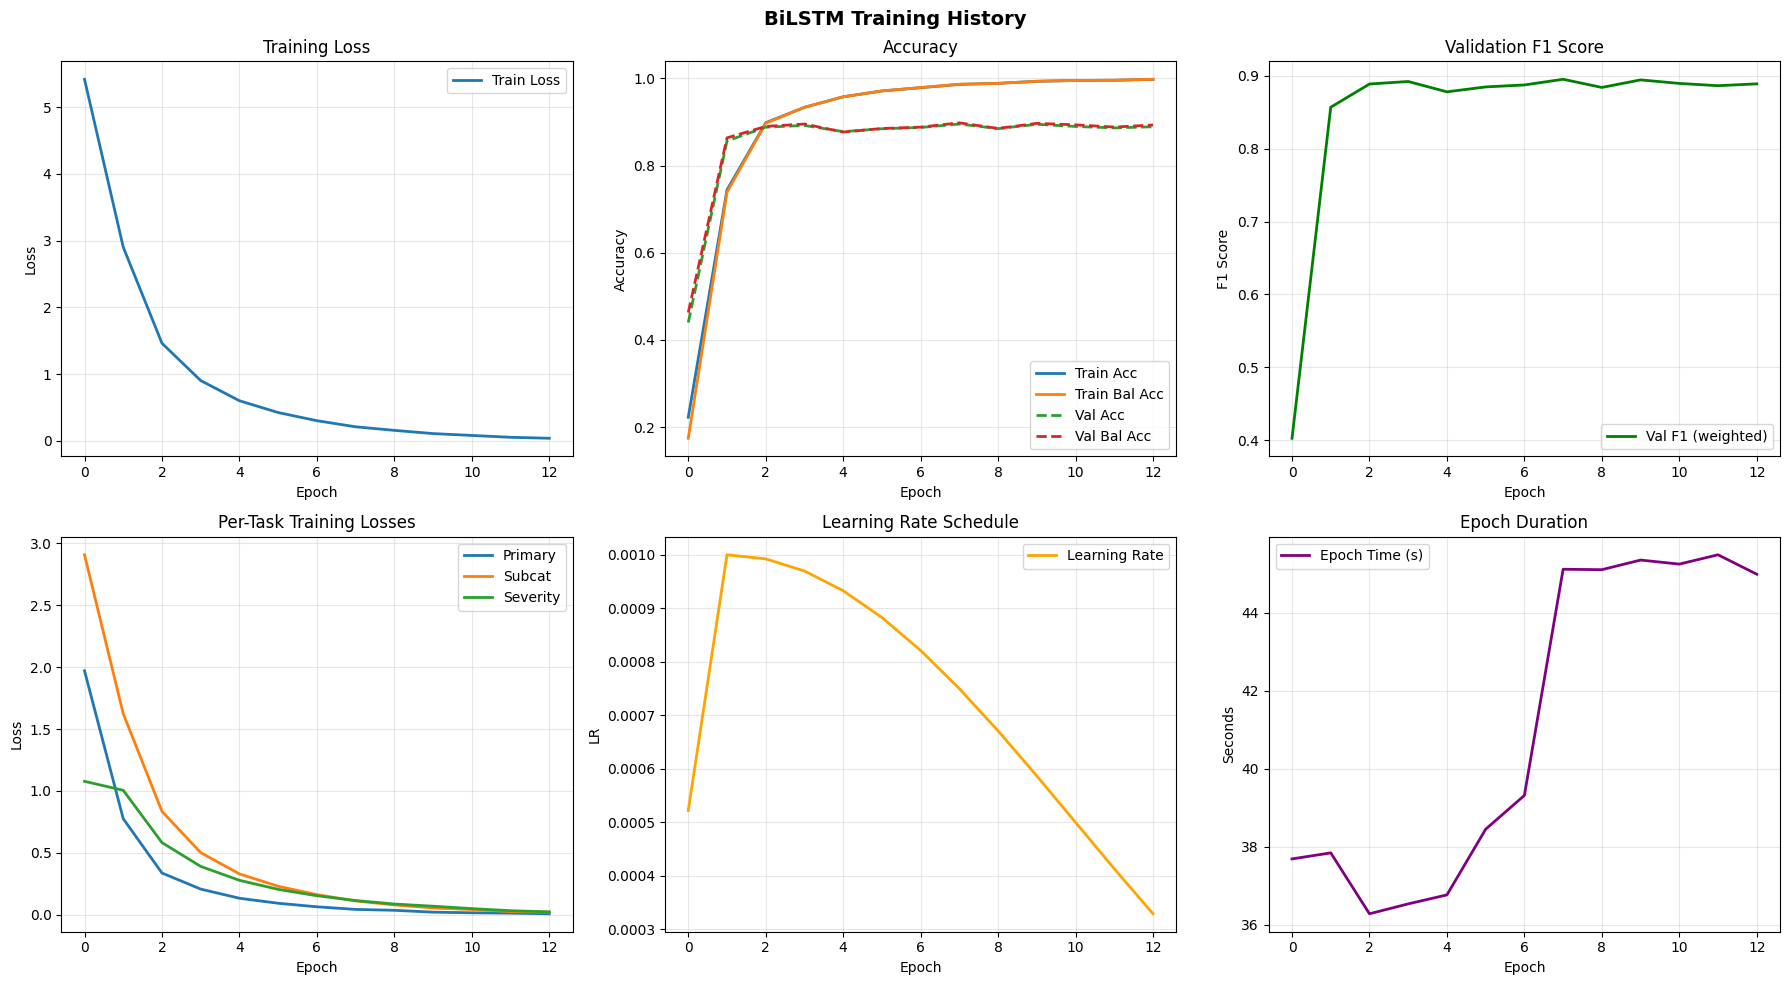

✅ Training history visualization saved


In [15]:
# ----------------------------------------------------------------------------
# CELL 14: TRAINING HISTORY VISUALIZATION (CONTINUED)
# ----------------------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2)
axes[0, 0].set_title('Training Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2)
axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2)
axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2, linestyle='--')
axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2, linestyle='--')
axes[0, 1].set_title('Accuracy')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1 (weighted)', linewidth=2, color='green')
axes[0, 2].set_title('Validation F1 Score')
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('F1 Score')
axes[0, 2].grid(True, alpha=0.3)
axes[0, 2].legend()

axes[1, 0].plot([h['task_losses']['primary'] for h in train_history], label='Primary', linewidth=2)
axes[1, 0].plot([h['task_losses']['subcat'] for h in train_history], label='Subcat', linewidth=2)
axes[1, 0].plot([h['task_losses']['severity'] for h in train_history], label='Severity', linewidth=2)
axes[1, 0].set_title('Per-Task Training Losses')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot([h['lr'] for h in train_history], label='Learning Rate', linewidth=2, color='orange')
axes[1, 1].set_title('Learning Rate Schedule')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('LR')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

axes[1, 2].plot([h['time'] for h in train_history], label='Epoch Time (s)', linewidth=2, color='purple')
axes[1, 2].set_title('Epoch Duration')
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Seconds')
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].legend()

plt.suptitle('BiLSTM Training History', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/training_history.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Training history visualization saved")

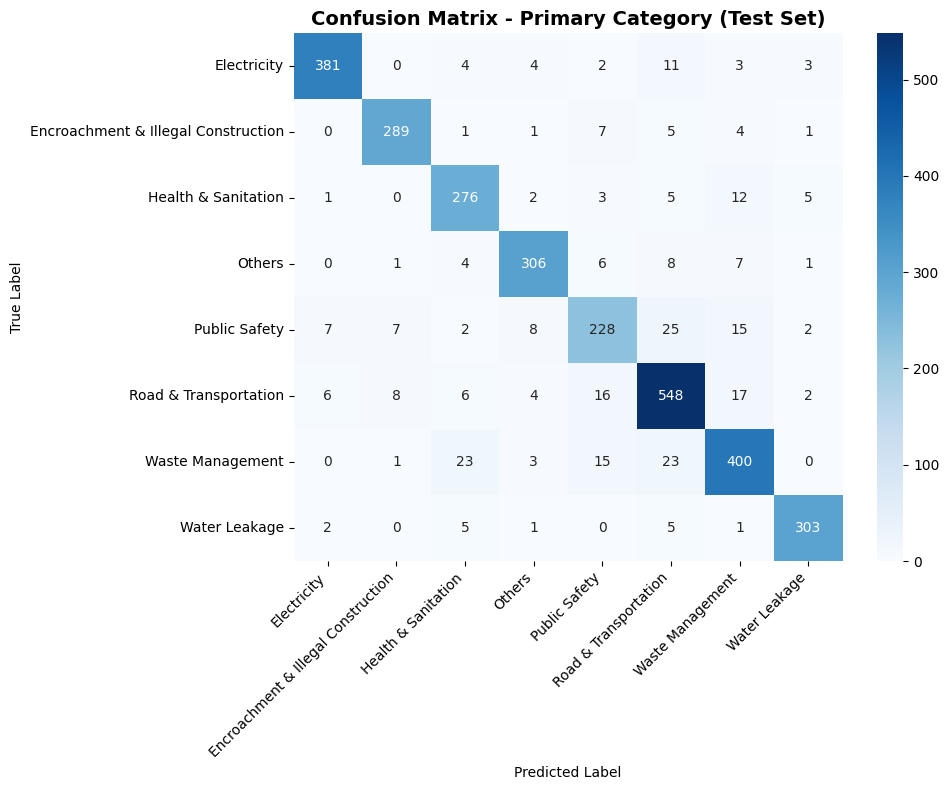

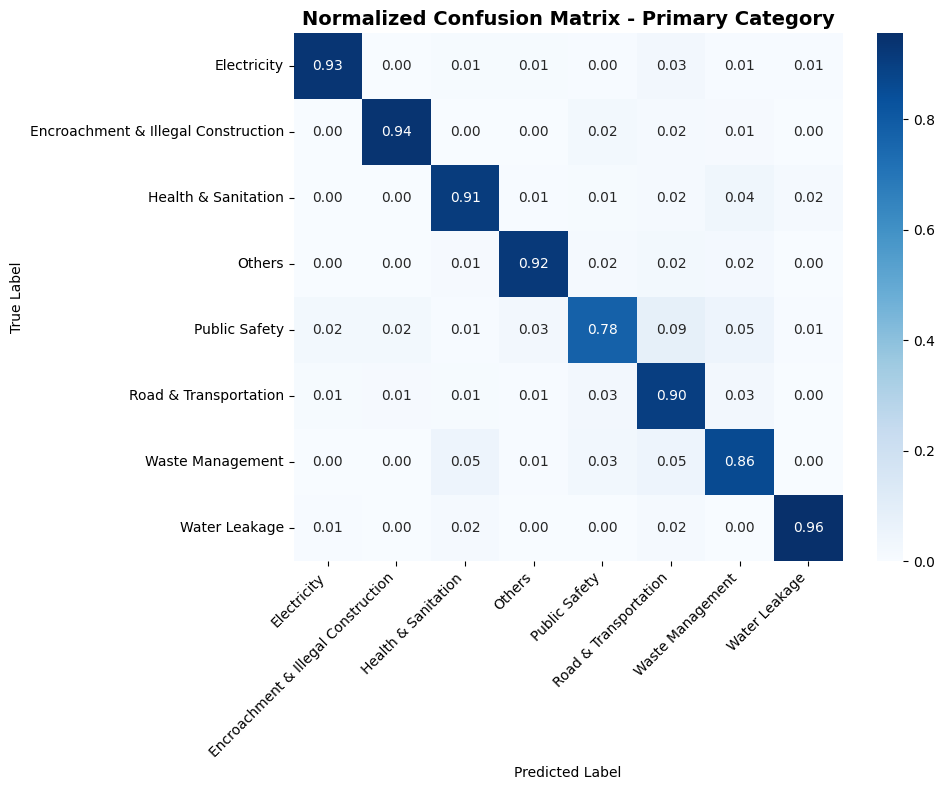

✅ Confusion matrices saved

CLASSIFICATION REPORT - PRIMARY CATEGORY
                                     precision    recall  f1-score   support

                        Electricity     0.9597    0.9338    0.9466       408
Encroachment & Illegal Construction     0.9444    0.9383    0.9414       308
                Health & Sanitation     0.8598    0.9079    0.8832       304
                             Others     0.9301    0.9189    0.9245       333
                      Public Safety     0.8231    0.7755    0.7986       294
              Road & Transportation     0.8698    0.9028    0.8860       607
                   Waste Management     0.8715    0.8602    0.8658       465
                      Water Leakage     0.9558    0.9558    0.9558       317

                           accuracy                         0.8995      3036
                          macro avg     0.9018    0.8992    0.9002      3036
                       weighted avg     0.8998    0.8995    0.8994      3036


✅ P

In [16]:
# ----------------------------------------------------------------------------
# CELL 15: CONFUSION MATRIX
# ----------------------------------------------------------------------------

cm = confusion_matrix(test_labels, test_preds)
class_names = preprocessor.le_primary.classes_

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Primary Category (Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.show()

# Normalized confusion matrix
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Normalized Confusion Matrix - Primary Category', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confusion_matrix_normalized.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Confusion matrices saved")

# ----------------------------------------------------------------------------
# CELL 16: CLASSIFICATION REPORT
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("CLASSIFICATION REPORT - PRIMARY CATEGORY")
print("="*80)

report = classification_report(
    test_labels, test_preds,
    target_names=class_names,
    digits=4,
    zero_division=0
)
print(report)

report_dict = classification_report(
    test_labels, test_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

with open(f"{Config.RESULTS_DIR}/classification_report.json", "w") as f:
    json.dump(report_dict, f, indent=2)

# Per-class metrics DataFrame
precision, recall, f1, support = precision_recall_fscore_support(
    test_labels, test_preds, labels=range(len(class_names)), zero_division=0
)
per_class_df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})
per_class_df.to_csv(f"{Config.RESULTS_DIR}/per_class_metrics.csv", index=False)
print(f"\n✅ Per-class metrics saved to {Config.RESULTS_DIR}")

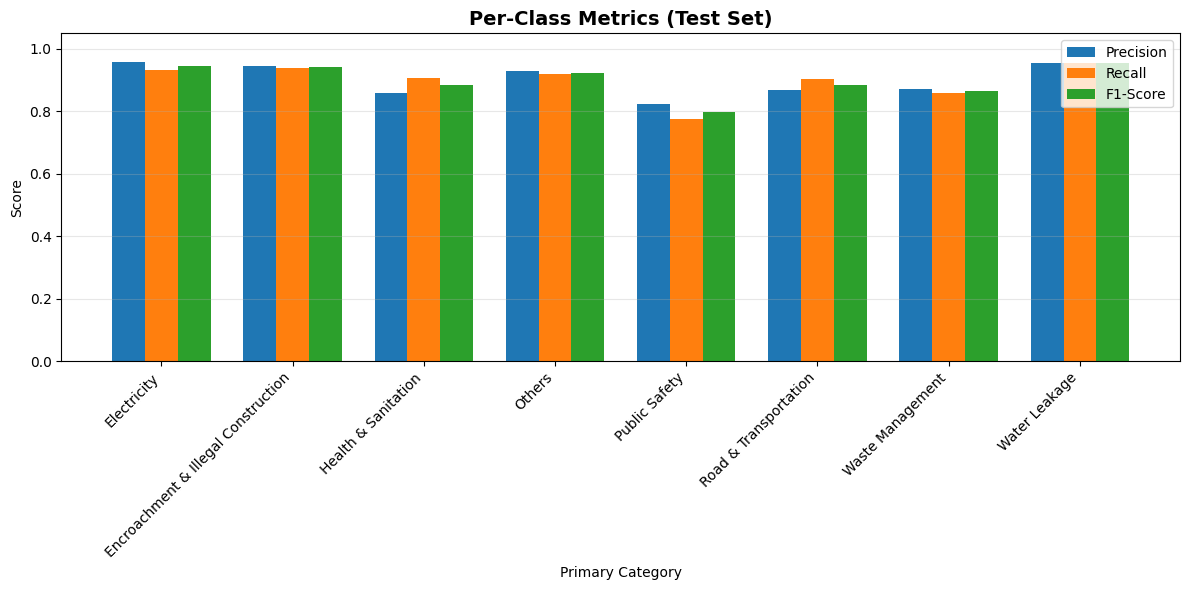

✅ Per-class metrics visualization saved


In [17]:
# ----------------------------------------------------------------------------
# CELL 17: PER-CLASS METRICS VISUALIZATION
# ----------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(class_names))
width = 0.25

ax.bar(x - width, precision, width, label='Precision')
ax.bar(x, recall, width, label='Recall')
ax.bar(x + width, f1, width, label='F1-Score')

ax.set_xlabel('Primary Category')
ax.set_ylabel('Score')
ax.set_title('Per-Class Metrics (Test Set)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/per_class_metrics.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Per-class metrics visualization saved")

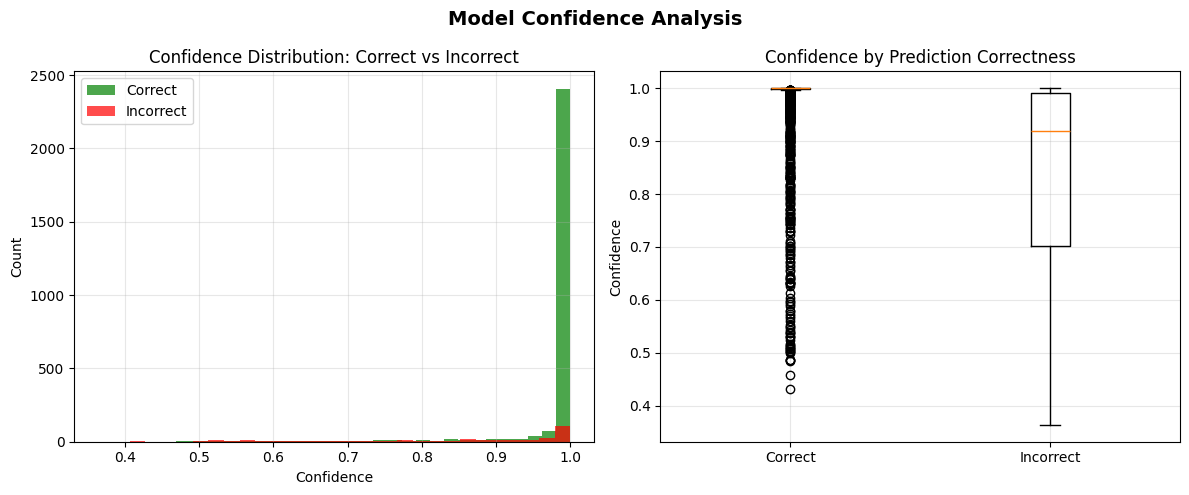


Confidence Stats:
  Correct predictions:   mean=0.9794, std=0.0737
  Incorrect predictions: mean=0.8444, std=0.1753


In [18]:
# ----------------------------------------------------------------------------
# CELL 18: CONFIDENCE DISTRIBUTION ANALYSIS
# ----------------------------------------------------------------------------

confidences = test_metrics['confidences']
correct_mask = np.array(test_preds) == np.array(test_labels)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(confidences[correct_mask], bins=30, alpha=0.7, label='Correct', color='green')
plt.hist(confidences[~correct_mask], bins=30, alpha=0.7, label='Incorrect', color='red')
plt.xlabel('Confidence')
plt.ylabel('Count')
plt.title('Confidence Distribution: Correct vs Incorrect')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.boxplot([confidences[correct_mask], confidences[~correct_mask]],
            labels=['Correct', 'Incorrect'])
plt.ylabel('Confidence')
plt.title('Confidence by Prediction Correctness')
plt.grid(True, alpha=0.3)

plt.suptitle('Model Confidence Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confidence_analysis.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"\nConfidence Stats:")
print(f"  Correct predictions:   mean={confidences[correct_mask].mean():.4f}, "
      f"std={confidences[correct_mask].std():.4f}")
print(f"  Incorrect predictions: mean={confidences[~correct_mask].mean():.4f}, "
      f"std={confidences[~correct_mask].std():.4f}")


Extracting embeddings for visualization...


Extracting embeddings: 100%|██████████| 24/24 [00:02<00:00, 11.83it/s]


✅ Embeddings shape: (3036, 1024)
Running t-SNE...


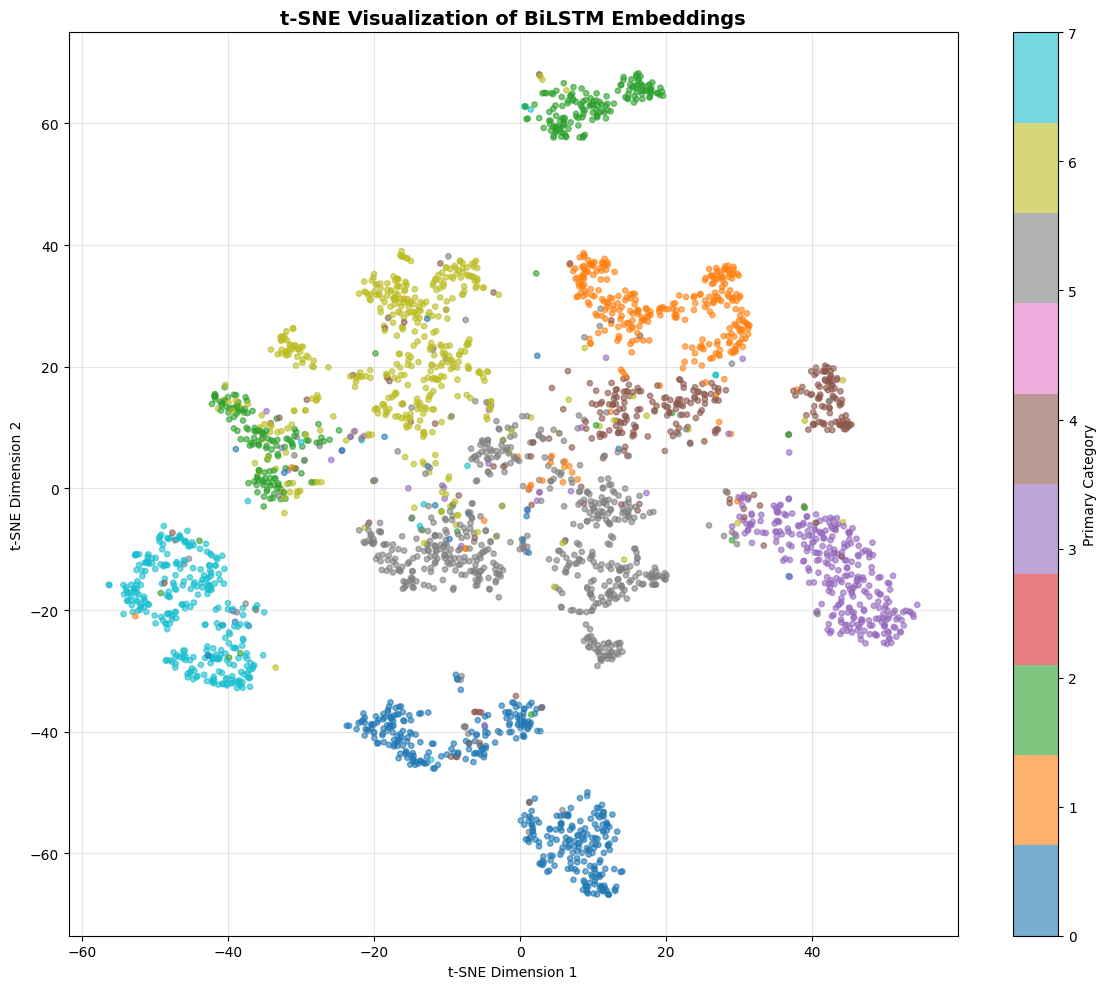

Running PCA...


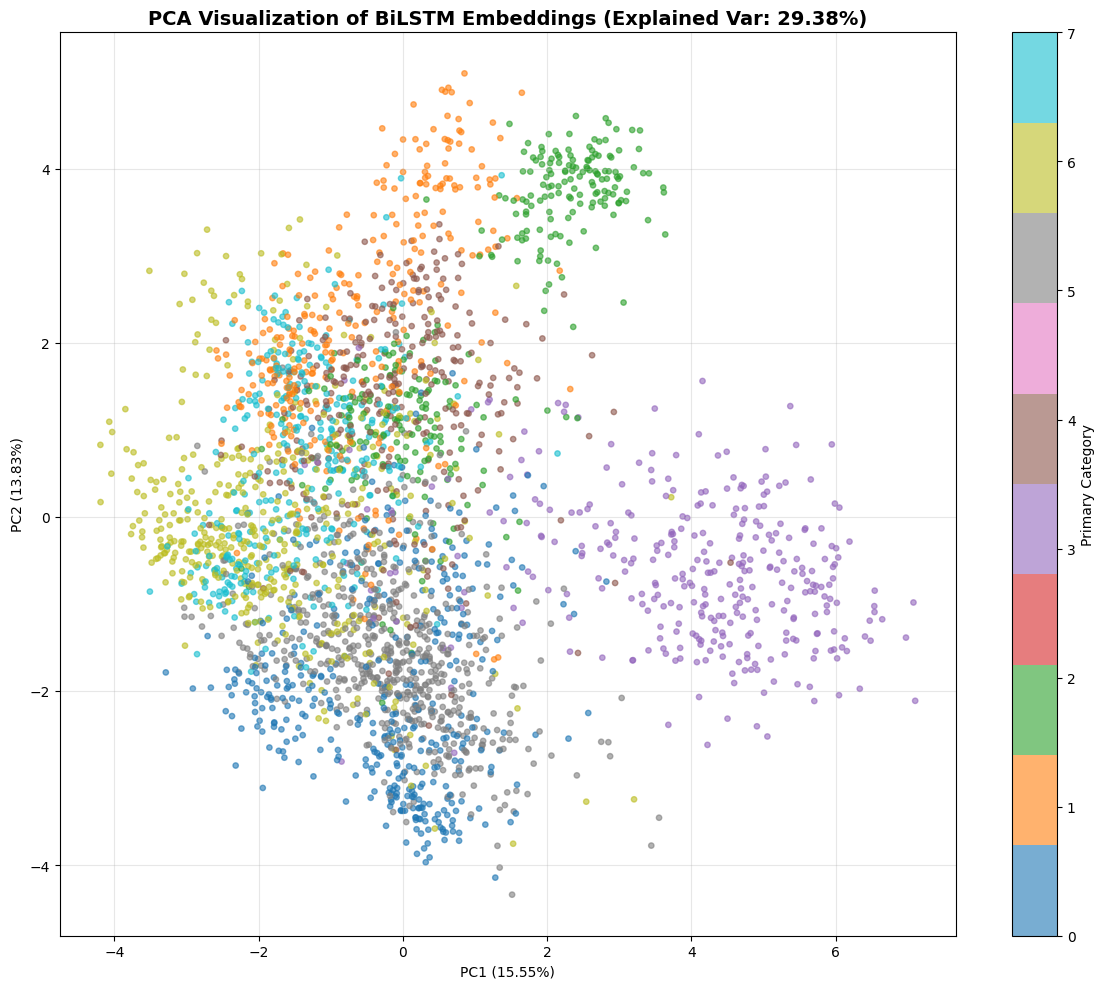

✅ Embedding visualizations saved


In [19]:
# ----------------------------------------------------------------------------
# CELL 19: EMBEDDING VISUALIZATION (t-SNE & PCA)
# ----------------------------------------------------------------------------

print("\nExtracting embeddings for visualization...")

model.eval()
all_embeddings = []
all_primary_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc='Extracting embeddings'):
        input_ids = batch['input_ids'].to(Config.DEVICE, non_blocking=True)
        attention_mask = batch['attention_mask'].to(Config.DEVICE, non_blocking=True)

        emb = model.get_embeddings(input_ids, attention_mask)
        all_embeddings.append(emb.cpu().numpy())
        all_primary_labels.extend(batch['primary'].cpu().numpy())

embeddings = np.vstack(all_embeddings)
primary_labels_arr = np.array(all_primary_labels)
print(f"✅ Embeddings shape: {embeddings.shape}")

# Subsample for t-SNE speed if large
MAX_TSNE_SAMPLES = 3000
if len(embeddings) > MAX_TSNE_SAMPLES:
    idx = np.random.choice(len(embeddings), MAX_TSNE_SAMPLES, replace=False)
    tsne_emb = embeddings[idx]
    tsne_labels = primary_labels_arr[idx]
else:
    tsne_emb = embeddings
    tsne_labels = primary_labels_arr

print("Running t-SNE...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
tsne_result = tsne.fit_transform(tsne_emb)

plt.figure(figsize=(12, 10))
scatter = plt.scatter(tsne_result[:, 0], tsne_result[:, 1],
                      c=tsne_labels, cmap='tab10', alpha=0.6, s=15)
plt.colorbar(scatter, label='Primary Category')
plt.title('t-SNE Visualization of BiLSTM Embeddings', fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png", dpi=300, bbox_inches='tight')
plt.show()

print("Running PCA...")
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(embeddings)

plt.figure(figsize=(12, 10))
scatter = plt.scatter(pca_result[:, 0], pca_result[:, 1],
                      c=primary_labels_arr, cmap='tab10', alpha=0.6, s=15)
plt.colorbar(scatter, label='Primary Category')
plt.title(f'PCA Visualization of BiLSTM Embeddings '
          f'(Explained Var: {pca.explained_variance_ratio_.sum():.2%})',
          fontsize=14, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/pca_embeddings.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Embedding visualizations saved")

In [20]:
# ----------------------------------------------------------------------------
# CELL 20: SAVE FINAL ARTIFACTS
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("SAVING FINAL ARTIFACTS")
print("="*80)

# Save vocabulary
with open(f"{Config.MODEL_DIR}/vocab.pkl", "wb") as f:
    pickle.dump(vocab, f)
print(f"✅ Vocabulary saved ({len(vocab)} tokens)")

# Save preprocessor / label encoders
with open(f"{Config.MODEL_DIR}/preprocessor.pkl", "wb") as f:
    pickle.dump(preprocessor, f)
print("✅ Preprocessor saved")

# Save final results summary
final_summary = {
    'base_model': Config.BASE_MODEL,
    'config': {
        'max_length': Config.MAX_LENGTH,
        'max_vocab_size': Config.MAX_VOCAB_SIZE,
        'embedding_dim': Config.EMBEDDING_DIM,
        'hidden_dim': Config.HIDDEN_DIM,
        'num_layers': Config.NUM_LAYERS,
        'bidirectional': Config.BIDIRECTIONAL,
        'dropout': Config.DROPOUT,
        'batch_size': Config.BATCH_SIZE,
        'learning_rate': Config.LEARNING_RATE,
        'epochs': Config.EPOCHS,
    },
    'num_classes': {
        'primary': n_primary,
        'subcat': n_subcat,
        'severity': n_severity,
    },
    'best_val_f1': float(best_val_f1),
    'best_val_balanced_acc': float(best_val_balanced_acc),
    'test_metrics': {k: float(v) for k, v in test_metrics.items()
                     if not isinstance(v, np.ndarray)},
    'training_time_min': total_time / 60,
    'epochs_trained': len(train_history),
    'timestamp': datetime.now().isoformat()
}

with open(f"{Config.RESULTS_DIR}/final_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2)

print(f"✅ Final summary saved to {Config.RESULTS_DIR}/final_summary.json")
print("\n" + "="*80)
print("🎉 PIPELINE COMPLETE")
print("="*80)
print(f"\nAll artifacts saved under: {Config.BASE_DIR}")
print(f"  Models:        {Config.MODEL_DIR}")
print(f"  Visualizations: {Config.VISUALIZATION_DIR}")
print(f"  Results:       {Config.RESULTS_DIR}")
print("="*80)


SAVING FINAL ARTIFACTS
✅ Vocabulary saved (29763 tokens)
✅ Preprocessor saved
✅ Final summary saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bilstm_results_CD\results/final_summary.json

🎉 PIPELINE COMPLETE

All artifacts saved under: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bilstm_results_CD
  Models:        C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bilstm_results_CD\models
  Visualizations: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bilstm_results_CD\visualizations
  Results:       C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bilstm_results_CD\results


GENERATING TABLES 14 & 15

--- Evaluating on the combined text ---
Pre-encoding dataset...
✅ Pre-encoded 3036 samples



--- Table 14: language-wise evaluation (text = that language only) ---

  English: 3036 samples | Devanagari chars: 0.0% | OOV tokens: 1.4%
    example: The Tender Sure footpath of St. Marks Road has been dug up by Sobha Builders. Please ensure that the
Pre-encoding dataset...
✅ Pre-encoded 3036 samples



  Hindi: 3036 samples | Devanagari chars: 99.8% | OOV tokens: 1.2%
    example: सेंट मार्क्स रोड के टेंडर श्योर फुटपाथ को शोभा बिल्डर्स ने खोद दिया है। कृपया सुनिश्चित करें कि अपूर
Pre-encoding dataset...
✅ Pre-encoded 3036 samples



  Hinglish: 3036 samples | Devanagari chars: 0.2% | OOV tokens: 3.9%
    example: Saint Marks Road ke Tender Sure footpath ko Sobha Builders ne khod diya hai. Kripya sunishchit karei
Pre-encoding dataset...
✅ Pre-encoded 3036 samples



TABLE 14: Language-wise Performance - Primary Category
 Model Language  Samples  Accuracy  F1-Macro  F1-Weighted  Precision   Recall  Cohen_Kappa      MCC
BiLSTM  English     3036  0.859025  0.858997     0.858283   0.859031 0.859025     0.837457 0.837673
BiLSTM    Hindi     3036  0.673584  0.661512     0.666387   0.695537 0.673584     0.619500 0.623532
BiLSTM Hinglish     3036  0.660408  0.659216     0.661025   0.679611 0.660408     0.605188 0.607294
BiLSTM Combined     3036  0.899539  0.900234     0.899435   0.899791 0.899539     0.883907 0.883978

TABLE 14b: Language x Task Performance (all three tasks)
 Model Language        Task  Samples  Accuracy  F1-Macro  F1-Weighted  Precision   Recall  Cohen_Kappa      MCC
BiLSTM  English     Primary     3036  0.859025  0.858997     0.858283   0.859031 0.859025     0.837457 0.837673
BiLSTM  English Subcategory     3036  0.722661  0.690762     0.718842   0.723926 0.722661     0.701203 0.701890
BiLSTM  English    Severity     3036  0.747694  0.

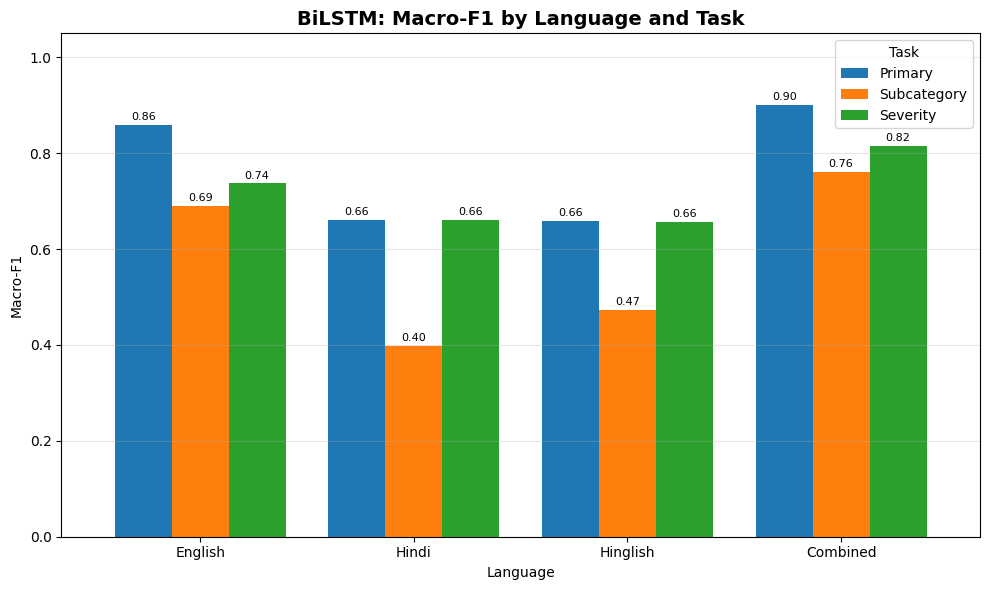

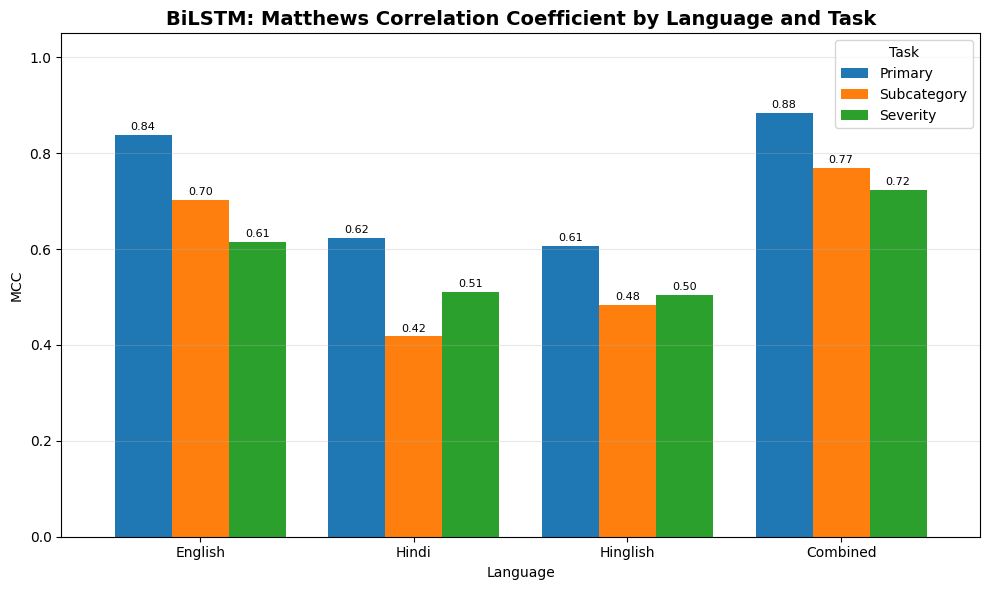


--- Table 15: task-wise evaluation (combined text) ---

TABLE 15: Category-wise Performance on Combined Dataset
 Model        Task  Accuracy  F1-Macro  F1-Weighted  Precision   Recall  Cohen_Kappa      MCC
BiLSTM     Primary  0.899539  0.900234     0.899435   0.899791 0.899539     0.883907 0.883978
BiLSTM Subcategory  0.785244  0.760391     0.784577   0.791439 0.785244     0.769719 0.769974
BiLSTM    Severity  0.815876  0.816010     0.818587   0.825426 0.815876     0.721332 0.723411

--- Saving LaTeX tables ---

✅ CSV, LaTeX and plot saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bilstm_results_CD\results / C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bilstm_results_CD\visualizations


In [22]:
# ----------------------------------------------------------------------------
# CELL 21: TABLES 14 & 15 (LANGUAGE-WISE AND TASK-WISE PERFORMANCE)
# ----------------------------------------------------------------------------
# Language-wise evaluation: the trained model is applied to the test set where the
# input text is ONLY the English / Hindi / Hinglish column (no title, no other
# language). Labels come from the already-preprocessed test_df, so rows and labels
# stay aligned and no label encoder is re-fitted.
from sklearn.metrics import matthews_corrcoef

def get_predictions(model, dataloader, device):
    """Run the model on a dataloader; return predictions and labels for all 3 tasks."""
    model.eval()
    preds = {'primary': [], 'subcat': [], 'severity': []}
    labels = {'primary': [], 'subcat': [], 'severity': []}

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Getting predictions", leave=False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            p1, p2, p3 = model(input_ids, attention_mask)

            preds['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
            preds['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
            preds['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
            for key in labels:
                labels[key].extend(batch[key].cpu().numpy())

    return {k: {'preds': np.array(preds[k]), 'labels': np.array(labels[k])} for k in preds}


def calculate_metrics(y_true, y_pred):
    """Full metric set for one task (including Matthews Correlation Coefficient)."""
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'F1-Macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'F1-Weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'Cohen_Kappa': cohen_kappa_score(y_true, y_pred),
        'MCC': matthews_corrcoef(y_true, y_pred)
    }


def build_language_df(df, col):
    """Monolingual copy of the preprocessed dataframe: text = ONLY column `col`."""
    if col not in df.columns:
        raise KeyError(f"Column '{col}' not in dataframe. Available: {list(df.columns)}")
    lang_df = df.copy()
    lang_df['text'] = (lang_df[col].fillna('').astype(str)
                       .str.replace(r"\s+", " ", regex=True).str.strip())
    lang_df = lang_df[lang_df['text'] != ''].reset_index(drop=True)
    return lang_df


def devanagari_fraction(texts):
    """Share of alphabetic characters that are Devanagari (script sanity check)."""
    dev = alpha = 0
    for t in texts:
        for ch in t:
            if ch.isalpha():
                alpha += 1
                if '\u0900' <= ch <= '\u097F':
                    dev += 1
    return dev / max(alpha, 1)


def oov_rate(texts, vocab):
    """Share of tokens that map to <unk> for this vocabulary."""
    total = unk = 0
    for t in texts:
        for tok in Vocabulary.tokenize(t):
            total += 1
            unk += tok not in vocab.word2idx
    return unk / max(total, 1)


TASKS = [('primary', 'Primary'), ('subcat', 'Subcategory'), ('severity', 'Severity')]

print("=" * 80)
print("GENERATING TABLES 14 & 15")
print("=" * 80)

# --- Combined (title + English + Hindi + Hinglish): the input the model was trained on ---
print("\n--- Evaluating on the combined text ---")
full_test_dataset = PreTokenizedDataset(test_df, vocab, Config.MAX_LENGTH)
full_test_loader = DataLoader(full_test_dataset, batch_size=Config.BATCH_SIZE * 2, shuffle=False)
all_predictions = get_predictions(model, full_test_loader, Config.DEVICE)

# --- Table 14: language-wise ---
print("\n--- Table 14: language-wise evaluation (text = that language only) ---")
language_results = []        # primary task only  (Table 14)
language_task_results = []   # every task x language (Table 14b)

for lang_name, col_name in Config.LANGUAGE_COLUMNS.items():
    lang_df = build_language_df(test_df, col_name)
    if len(lang_df) == 0:
        print(f"⚠️ No non-empty text in '{col_name}'. Skipping {lang_name}.")
        continue

    dev_frac = devanagari_fraction(lang_df['text'].tolist())
    oov = oov_rate(lang_df['text'].tolist(), vocab)
    print(f"\n  {lang_name}: {len(lang_df)} samples | Devanagari chars: {dev_frac:.1%} | "
          f"OOV tokens: {oov:.1%}")
    print(f"    example: {lang_df['text'].iloc[0][:100]}")
    if lang_name == 'Hindi' and dev_frac < 0.5:
        print("    ⚠️ 'Hindi' column is mostly NOT Devanagari - check the column mapping.")
    if lang_name in ('English', 'Hinglish') and dev_frac > 0.1:
        print(f"    ⚠️ '{lang_name}' column contains Devanagari text - check the column mapping.")

    lang_dataset = PreTokenizedDataset(lang_df, vocab, Config.MAX_LENGTH)
    lang_loader = DataLoader(lang_dataset, batch_size=Config.BATCH_SIZE * 2, shuffle=False)
    predictions = get_predictions(model, lang_loader, Config.DEVICE)

    for task_key, task_name in TASKS:
        m = calculate_metrics(predictions[task_key]['labels'], predictions[task_key]['preds'])
        if task_key == 'primary':
            language_results.append({'Model': 'BiLSTM', 'Language': lang_name, 'Samples': len(lang_df), **m})
        language_task_results.append({'Model': 'BiLSTM', 'Language': lang_name, 'Task': task_name,
                                      'Samples': len(lang_df), **m})

# Combined rows
for task_key, task_name in TASKS:
    m = calculate_metrics(all_predictions[task_key]['labels'], all_predictions[task_key]['preds'])
    if task_key == 'primary':
        language_results.append({'Model': 'BiLSTM', 'Language': 'Combined', 'Samples': len(test_df), **m})
    language_task_results.append({'Model': 'BiLSTM', 'Language': 'Combined', 'Task': task_name,
                                  'Samples': len(test_df), **m})

metric_cols = ['Accuracy', 'F1-Macro', 'F1-Weighted', 'Precision', 'Recall', 'Cohen_Kappa', 'MCC']

df_table14 = pd.DataFrame(language_results)[['Model', 'Language', 'Samples'] + metric_cols]
print("\n" + "=" * 80)
print("TABLE 14: Language-wise Performance - Primary Category")
print("=" * 80)
print(df_table14.to_string(index=False))
df_table14.to_csv(f"{Config.RESULTS_DIR}/table14_language_performance.csv", index=False)

df_table14b = pd.DataFrame(language_task_results)[['Model', 'Language', 'Task', 'Samples'] + metric_cols]
print("\n" + "=" * 80)
print("TABLE 14b: Language x Task Performance (all three tasks)")
print("=" * 80)
print(df_table14b.to_string(index=False))
df_table14b.to_csv(f"{Config.RESULTS_DIR}/table14b_language_task_performance.csv", index=False)

# Plot: Macro-F1 per language and task
pivot = df_table14b.pivot(index='Language', columns='Task', values='F1-Macro')
order = [l for l in list(Config.LANGUAGE_COLUMNS.keys()) + ['Combined'] if l in pivot.index]
pivot = pivot.loc[order, [t for _, t in TASKS]]
ax = pivot.plot(kind='bar', figsize=(10, 6), width=0.8)
ax.set_ylabel('Macro-F1')
ax.set_ylim(0, 1.05)
ax.set_title('BiLSTM: Macro-F1 by Language and Task', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=8, padding=2)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/language_wise_performance.png", dpi=300, bbox_inches='tight')
plt.show()

# Plot: MCC per language and task
pivot_mcc = df_table14b.pivot(index='Language', columns='Task', values='MCC')
pivot_mcc = pivot_mcc.loc[order, [t for _, t in TASKS]]
ax_mcc = pivot_mcc.plot(kind='bar', figsize=(10, 6), width=0.8)
ax_mcc.set_ylabel('MCC')
ax_mcc.set_ylim(0, 1.05)
ax_mcc.set_title('BiLSTM: Matthews Correlation Coefficient by Language and Task',
                 fontsize=14, fontweight='bold')
ax_mcc.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=0)
for container in ax_mcc.containers:
    ax_mcc.bar_label(container, fmt='%.2f', fontsize=8, padding=2)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/language_wise_mcc.png", dpi=300, bbox_inches='tight')
plt.show()

# --- Table 15: task-wise (combined text) ---
print("\n--- Table 15: task-wise evaluation (combined text) ---")
task_results = []
for task_key, task_name in TASKS:
    m = calculate_metrics(all_predictions[task_key]['labels'], all_predictions[task_key]['preds'])
    task_results.append({'Model': 'BiLSTM', 'Task': task_name, **m})

df_table15 = pd.DataFrame(task_results)[['Model', 'Task'] + metric_cols]
print("\n" + "=" * 80)
print("TABLE 15: Category-wise Performance on Combined Dataset")
print("=" * 80)
print(df_table15.to_string(index=False))
df_table15.to_csv(f"{Config.RESULTS_DIR}/table15_category_performance.csv", index=False)

# --- LaTeX versions ---
print("\n--- Saving LaTeX tables ---")
latex_files = {
    'table14_language_performance.tex': df_table14.to_latex(
        index=False, float_format="%.4f",
        caption="Language-wise Performance (Primary Category) of BiLSTM",
        label="tab:language_performance_bilstm"),
    'table14b_language_task_performance.tex': df_table14b.to_latex(
        index=False, float_format="%.4f",
        caption="Language and Task-wise Performance of BiLSTM",
        label="tab:language_task_performance_bilstm"),
    'table15_category_performance.tex': df_table15.to_latex(
        index=False, float_format="%.4f",
        caption="Category-wise Performance on Combined Dataset (BiLSTM)",
        label="tab:category_performance_bilstm"),
}
for fname, tex in latex_files.items():
    with open(f"{Config.RESULTS_DIR}/{fname}", "w") as f:
        f.write(tex)

print(f"\n✅ CSV, LaTeX and plot saved to {Config.RESULTS_DIR} / {Config.VISUALIZATION_DIR}")
print("=" * 80)